# Padé approximation as a tool

`pyharminv.padeapprox` is a general robust Padé approximation routine (the
algorithm of Gonnet, Güttel and Trefethen, translated from Chebfun). This
notebook shows what Padé approximants can do on their own, independent of
harmonic inversion, following chapter 27 of Trefethen's *Approximation
Theory and Approximation Practice*.

A type $(m, n)$ Padé approximant of a function with Taylor series
$f(x) = \sum_k c_k x^k$ is the rational function $r = p/q$ with
$\deg p \le m$, $\deg q \le n$ whose Taylor series agrees with that of $f$
as far as possible, normally up to $x^{m+n}$. It uses the same
coefficients as the Taylor polynomial of degree $m+n$, but is often far more
accurate, and it works beyond the radius of convergence.

In [1]:
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
from pyharminv import padeapprox, taylor_coeffs

plt.rcParams["figure.figsize"] = (9, 4)

## 1. A first example: the exponential

`padeapprox` accepts Taylor coefficients or a function (whose
coefficients it computes by FFT on the unit circle). The result has the
coefficients of $p$ and $q$ in ascending powers, the exact degrees, poles,
zeros and residues, and can be evaluated like a function.

In [2]:
c = 1 / np.array([math.factorial(k) for k in range(5)], dtype=float)
r = padeapprox(c, 2, 2)
print("p:", r.a)        # 1 + x/2 + x^2/12
print("q:", r.b)        # 1 - x/2 + x^2/12
print("poles:", r.poles)

p: [1.         0.5        0.08333333]
q: [ 1.         -0.5         0.08333333]
poles: [3.+1.73205081j 3.-1.73205081j]


With the same five coefficients the Taylor polynomial of degree 4 is
much less accurate over a wide interval than the (2, 2) approximant:

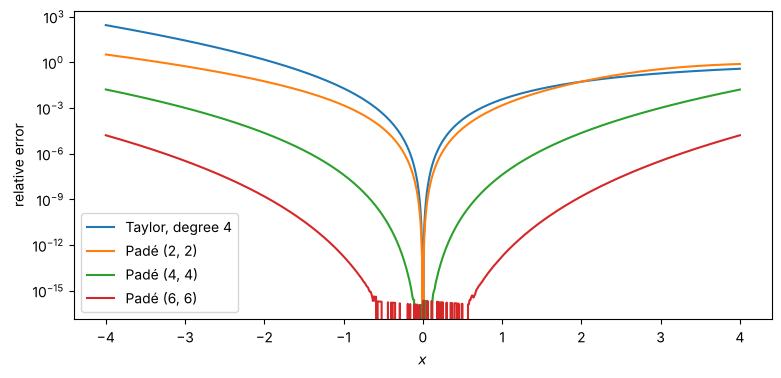

In [3]:
x = np.linspace(-4, 4, 801)
taylor = np.polyval(c[::-1], x)
plt.semilogy(x, np.abs(taylor - np.exp(x)) / np.exp(x), label="Taylor, degree 4")
plt.semilogy(x, np.abs(r(x) - np.exp(x)) / np.exp(x), label="Padé (2, 2)")
for n in [4, 6]:
    rn = padeapprox(np.exp, n, n)
    plt.semilogy(x, np.abs(rn(x) - np.exp(x)) / np.exp(x), label=f"Padé ({n}, {n})")
plt.xlabel("$x$"); plt.ylabel("relative error"); plt.legend();

## 2. Beyond the radius of convergence

The Taylor series of $\log(1+x)$ converges only for $|x| < 1$, because of
the singularity at $x = -1$. Padé approximants from the very same
coefficients converge on the whole plane cut along $(-\infty, -1]$. To do
so, they place their poles and zeros along the branch cut, where they
imitate the jump of the logarithm.

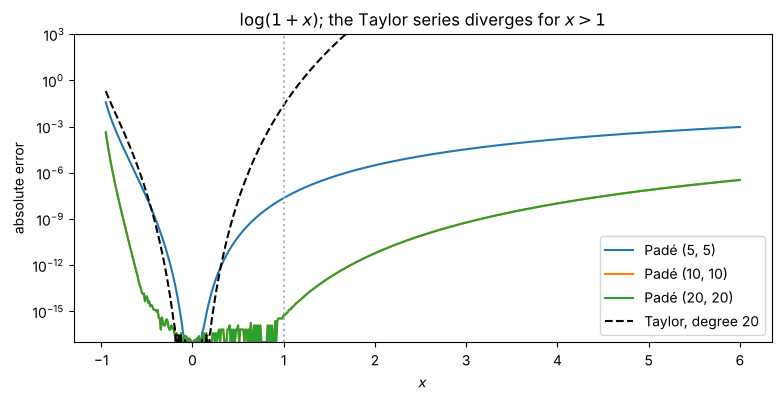

In [4]:
n_coef = 41
c = np.array([0.0] + [(-1) ** (k + 1) / k for k in range(1, n_coef)])
x = np.linspace(-0.95, 6, 600)

for deg in [5, 10, 20]:
    taylor = np.polyval(c[:2 * deg + 1][::-1], x)
    r = padeapprox(c, deg, deg)
    plt.semilogy(x, np.abs(r(x) - np.log1p(x)) + 1e-17, label=f"Padé ({deg}, {deg})")
plt.semilogy(x, np.abs(np.polyval(c[:21][::-1], x) - np.log1p(x)), "k--",
             label="Taylor, degree 20")
plt.axvline(1, color="0.7", ls=":")
plt.ylim(1e-17, 1e3); plt.xlabel("$x$"); plt.ylabel("absolute error")
plt.title(r"$\log(1+x)$; the Taylor series diverges for $x > 1$"); plt.legend();

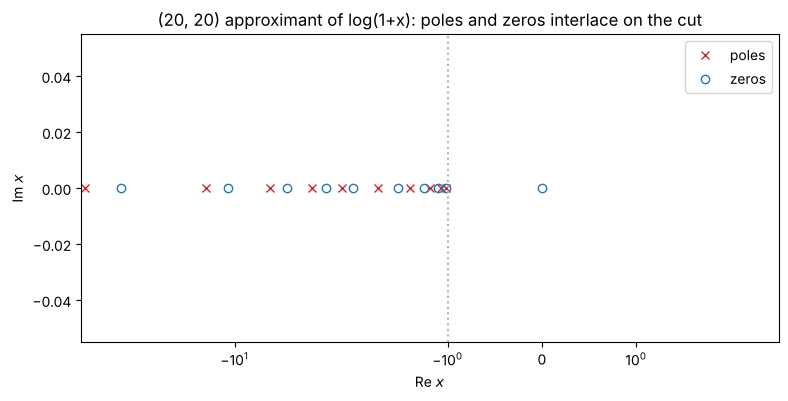

In [5]:
r = padeapprox(c, 20, 20)
plt.plot(r.poles.real, r.poles.imag, "x", color="C3", label="poles")
plt.plot(r.zeros.real, r.zeros.imag, "o", mfc="none", color="C0", label="zeros")
plt.axvline(-1, color="0.7", ls=":")
plt.xscale("symlog"); plt.xlabel("Re $x$"); plt.ylabel("Im $x$")
plt.title("(20, 20) approximant of log(1+x): poles and zeros interlace on the cut")
plt.legend();

## 3. Locating poles: the tangent

For a meromorphic function the poles of Padé approximants converge to the
poles of the function, again from Taylor coefficients at a single point.
The tangent has poles at $\pm\pi/2, \pm 3\pi/2, \dots$, while its Taylor
series converges only for $|x| < \pi/2$.

In [6]:
c = taylor_coeffs(np.tan, n=2048)[:60]   # tan is analytic on the unit disc
true_poles = (np.arange(1, 6) - 0.5) * np.pi
print("  n   pole errors for pi/2, 3pi/2, 5pi/2, 7pi/2")
for n in [2, 4, 8, 12, 16]:
    r = padeapprox(c, n + 1, n)
    found = np.sort(r.poles.real[(r.poles.real > 0) & (np.abs(r.poles.imag) < 1e-6)])
    errs = [np.min(np.abs(found - p)) if len(found) else np.nan for p in true_poles[:4]]
    print(f"{n:3d}  " + "  ".join(f"{e:9.1e}" for e in errs))

  n   pole errors for pi/2, 3pi/2, 5pi/2, 7pi/2
  2    1.0e-02    3.1e+00    6.3e+00    9.4e+00
  4    1.2e-05    3.4e-01    2.8e+00    5.9e+00
  8    2.5e-13    8.2e-05    1.2e-01    3.0e+00
 12    2.5e-13    8.2e-05    1.2e-01    3.0e+00
 16    2.5e-13    8.2e-05    1.2e-01    3.0e+00


The nearest pole converges fast: its error falls from $10^{-2}$ to
$10^{-13}$ between $n = 2$ and $n = 8$. The outer poles converge more slowly,
and from $n = 8$ on nothing improves. That is not a flaw of the method but of
double precision: the pole at $3\pi/2$ shows up in the coefficients only as a
correction of relative size $3^{-k}$ to the dominant $(2/\pi)^k$ decay, and
after about 30 coefficients this correction is below rounding. The robust
algorithm notices that the Toeplitz matrix has numerical rank 8 and keeps
$\nu = 8$ however large an $n$ we ask for (with `tol=0` it returns more
poles, but they do not get more accurate). More poles need more digits, or
Taylor coefficients about a point closer to them.

degree of the denominator actually used: 8


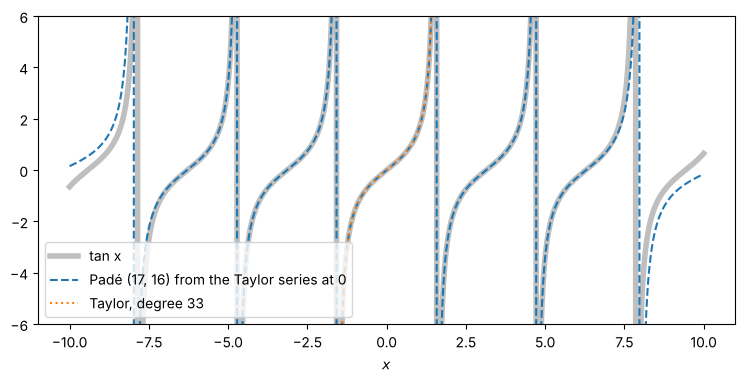

In [7]:
r = padeapprox(c, 17, 16)
print("degree of the denominator actually used:", r.nu)
x = np.linspace(-10, 10, 2001)
with np.errstate(divide="ignore", invalid="ignore"):
    plt.plot(x, np.tan(x), color="0.75", lw=4, label="tan x")
    plt.plot(x, r(x), "--", label="Padé (17, 16) from the Taylor series at 0")
    plt.plot(x, np.polyval(c[:34][::-1], x), ":", label="Taylor, degree 33")
plt.ylim(-6, 6); plt.xlabel("$x$"); plt.legend(loc="lower left");

The approximant reproduces the tangent across several poles; the
Taylor polynomial of the same degree breaks down at $|x| = \pi/2$.

## 4. Summing a divergent series

The Euler series $\sum_k (-1)^k k!\, x^k$ diverges for every $x \ne 0$, yet
it is the asymptotic expansion of the Stieltjes function
$$f(x) = \int_0^\infty \frac{e^{-t}}{1 + x t}\, dt .$$
Its Padé approximants converge to $f$. This is how Padé approximants
extract meaning from asymptotic series, e.g. in perturbation theory.

In [8]:
from scipy.integrate import quad

def stieltjes(x):
    return quad(lambda t: np.exp(-t) / (1 + x * t), 0, np.inf)[0]

c = np.array([(-1) ** k * math.factorial(k) for k in range(30)], dtype=float)
xs = [0.1, 0.5, 1.0, 2.0]
print("   n " + "".join(f"   x = {x:<10}" for x in xs))
for n in [2, 4, 6, 8, 10, 12]:
    r = padeapprox(c, n - 1, n, tol=0)
    print(f"{n:4d} " + "".join(f"   {abs(r(x) / stieltjes(x) - 1):<14.1e}" for x in xs))
print("partial sums of the series at x = 0.5:",
      [f"{np.sum(c[:k] * 0.5 ** np.arange(k)):.3g}" for k in (5, 10, 15)])

   n    x = 0.1          x = 0.5          x = 1.0          x = 2.0       
   2    1.5e-04          1.2e-02          4.2e-02          1.1e-01       
   4    3.2e-07          6.0e-04          5.1e-03          2.5e-02       
   6    2.0e-09          5.6e-05          9.5e-04          7.5e-03       
   8    2.5e-11          7.3e-06          2.2e-04          2.7e-03       
  10    2.8e-13          1.2e-06          6.1e-05          1.1e-03       
  12    1.9e-13          2.3e-07          1.9e-05          4.8e-04       
partial sums of the series at x = 0.5: ['1.75', '-581', '4.66e+06']


The partial sums run away, while the approximants converge, more
slowly for larger $x$. (`tol=0` switches the rank reduction off; the
coefficients span many orders of magnitude, which would otherwise be
mistaken for rank deficiency.)

## 5. Robustness: Froissart doublets

Padé approximation is notoriously sensitive to noise and rounding: the
classic algorithm produces spurious pole-zero pairs, *Froissart doublets*,
that nearly cancel each other. The robust algorithm detects the effective
degree from the singular values and removes them. We approximate $e^x$
from coefficients with noise of size $10^{-10}$:

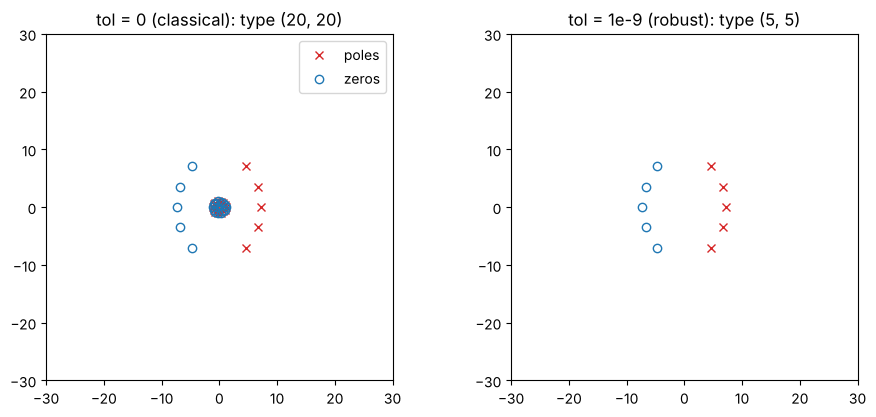

In [9]:
rng = np.random.default_rng(0)
c = 1 / np.array([math.factorial(k) for k in range(41)], dtype=float)
c_noisy = c + 1e-10 * rng.standard_normal(len(c))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, tol, title in [(axes[0], 0, "tol = 0 (classical)"),
                       (axes[1], 1e-9, "tol = 1e-9 (robust)")]:
    r = padeapprox(c_noisy, 20, 20, tol=tol)
    ax.plot(r.poles.real, r.poles.imag, "x", color="C3", label="poles")
    ax.plot(r.zeros.real, r.zeros.imag, "o", mfc="none", color="C0", label="zeros")
    ax.set_title(f"{title}: type ({r.mu}, {r.nu})")
    ax.set_xlim(-30, 30); ax.set_ylim(-30, 30); ax.set_aspect("equal")
axes[0].legend();

Without robustness most poles of the (20, 20) approximant are doublets
(a cross with a circle on top). The robust approximant reduces the type to
what the data supports and has no doublets. The same mechanism removes
spurious modes in harmonic inversion.

## 6. Degenerate cases: square blocks in the Padé table

For even or otherwise structured functions the Padé table contains square
blocks of identical approximants, and the classical linear equations become
singular. The robust algorithm returns the exact type of the block:

In [10]:
# 1/(1 - x^2) has poles on the unit circle, so we pass its coefficients
geometric_even = np.tile([1.0, 0.0], 20)
for f, name in [(np.cos, "cos"), (geometric_even, "1/(1-x^2)"),
                (lambda x: np.exp(x ** 3), "exp(x^3)")]:
    for m, n in [(4, 4), (5, 5), (7, 6)]:
        r = padeapprox(f, m, n)
        print(f"{name:10s} requested ({m}, {n}) -> exact type ({r.mu}, {r.nu})")

cos        requested (4, 4) -> exact type (4, 4)
cos        requested (5, 5) -> exact type (4, 4)
cos        requested (7, 6) -> exact type (6, 6)
1/(1-x^2)  requested (4, 4) -> exact type (0, 2)
1/(1-x^2)  requested (5, 5) -> exact type (0, 2)
1/(1-x^2)  requested (7, 6) -> exact type (0, 2)
exp(x^3)   requested (4, 4) -> exact type (3, 3)
exp(x^3)   requested (5, 5) -> exact type (3, 3)
exp(x^3)   requested (7, 6) -> exact type (6, 6)


## 7. The link to harmonic inversion

A signal $c_n = \sum_k d_k z_k^n$ is the Taylor series of
$\sum_k d_k / (1 - z_k x)$. Its Padé approximant therefore recovers
$z_k = 1/x_k$ and $d_k = -\mathrm{Res}_{x_k}/x_k$ exactly, which is the Padé
solver of `harminv`:

In [11]:
dt = 0.1
omega = np.array([3.0 - 0.05j, 7.0 - 0.02j])
d = np.array([1.0, 0.8j])
n = np.arange(20)
c = (d * np.exp(-1j * np.outer(n * dt, omega))).sum(axis=1)

r = padeapprox(c, 9, 10)
print("type:", (r.mu, r.nu))
print("omega =", -1j * np.log(r.poles) / dt)
print("d     =", -r.residues / r.poles)

type: (1, 2)
omega = [3.-0.05j 7.-0.02j]
d     = [ 1.00000000e+00-1.30335308e-14j -2.55082093e-14+8.00000000e-01j]


Twenty samples, two modes: the approximant reduces itself to type
(1, 2) and returns both frequencies and amplitudes to rounding accuracy.

## Further reading

* L. N. Trefethen, *Approximation Theory and Approximation Practice*,
  SIAM (2013), chapters 26–28.
* P. Gonnet, S. Güttel and L. N. Trefethen, "Robust Padé approximation via
  SVD", SIAM Review 55, 101 (2013).
* G. A. Baker and P. Graves-Morris, *Padé Approximants*, Cambridge (1996).